# Instructions

1. Problème de retard entre enregistrements
    - Charger les deux fichiers audio drums.wav et drums_delayed.wav
    - Les normaliser de sorte à ce que leur valeur maximale absolue soit égale à 1, les écouter
    - Tracer les premières 0.1 sec de chaque waveform sur la même figure (ajouter +1 à l'un des deux vecteurs pour simplifier la visualisation)
    - Les additionner en utilisant la fonction `add_np_arrays`, écouter le résultat et commenter

2. Estimer/corriger un retard avec l'inter-correlation 
    - Utiliser la fonction `correlate` du module `scipy.signal` pour estimer le retard entre les deux enregistrements
    - Corriger ce retard retardant l'un des deux enregistrements à l'aide de la méthode `pad` du module `numpy`
    - Tracer les deux waveforms comme précédemment pour vérifier l'alignement
    - Additionner les deux enregistrements et écouter le résultat

In [ ]:
# import 
import numpy as np

# performs term-wise array1 + array2 after zero padding (end) the shortest for equal size
def add_np_arrays(array1, array2):
    if( len(array2) > len(array1) ):
        array1 = np.pad(array1, [0, len(array2) - len(array1)])
    else:
        array2 = np.pad(array2, [0, len(array1) - len(array2)])
    return (array1 + array2) / 2

# Correction

In [2]:
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

## 1. Problème de retard entre enregistrements

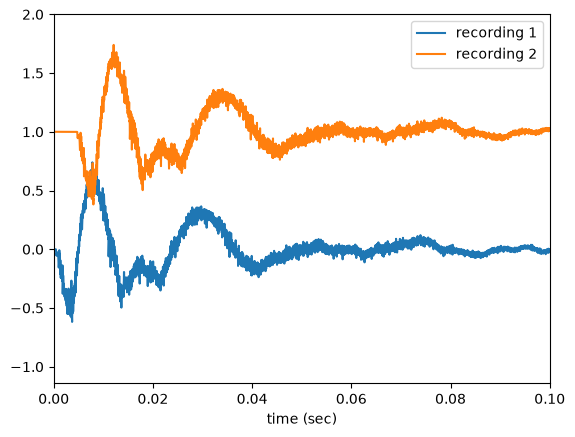

In [3]:
# load audio 
fs, audio1 = scipy.io.wavfile.read('../assets/drums.wav')
fs, audio2 = scipy.io.wavfile.read('../assets/drums_delayed.wav')

# normalise
audio1 = audio1 / np.max(np.abs(audio1))
audio2 = audio2 / np.max(np.abs(audio2))

# play
display(Audio(audio1, rate=fs))
display(Audio(audio2, rate=fs))
audio_out = add_np_arrays(audio1, audio2)
display(Audio(audio_out, rate=fs))

# plot
t1 = np.arange(len(audio1)) / fs
t2 = np.arange(len(audio2)) / fs
plt.plot(t1, audio1, label = 'recording 1')
plt.plot(t2, audio2+1, label = 'recording 2')
plt.xlabel('time (sec)'); plt.legend();
plt.xlim([0, 0.1])
plt.show()


## 2. Estimer/corriger un retard avec l'inter-correlation 

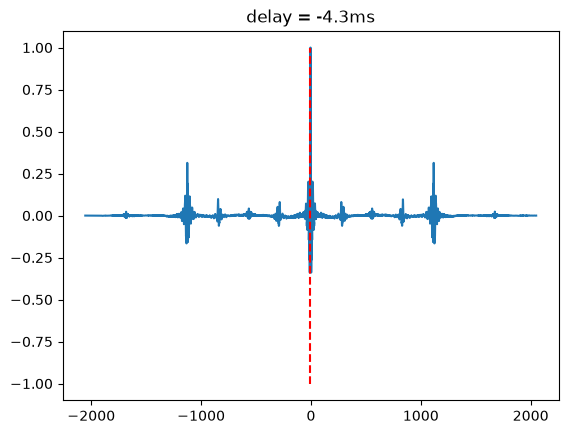

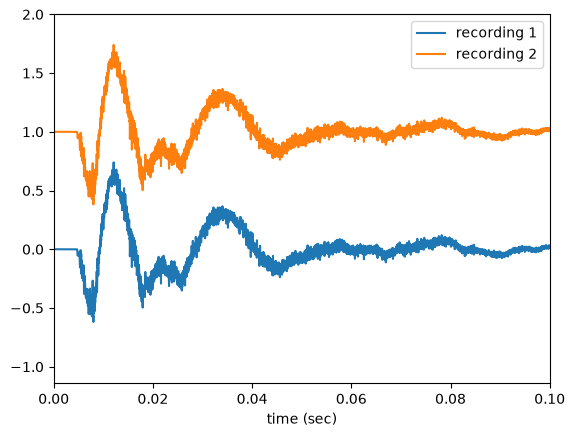

In [4]:
# estimate delay using correlation
corr = scipy.signal.correlate(audio1, audio2, mode='full', method='fft')
delay_in_samp = np.argmax(corr) - (len(audio2) - 1)
delay_in_ms = 1000 * delay_in_samp / fs

# # could also estimate using correlation_lags
# lags = scipy.signal.correlation_lags(len(audio1), len(audio2), mode='full')
# delay_in_samp = lags[np.argmax(corr)]

# plot
lags = np.arange(-len(audio2)+1, len(audio1))
plt.plot(1000*lags/fs, corr / np.max(np.abs(corr)))
plt.plot([delay_in_ms, delay_in_ms], [-1, 1], '--r')
plt.title(f'delay = {delay_in_ms:0.1f}ms')
# o = 100; plt.xlim([delay_in_ms-o, delay_in_ms+o])
plt.show()

# realign
if( delay_in_samp < 0 ):
    audio1_aligned = np.pad(audio1, [-delay_in_samp, 0])
    audio2_aligned = audio2
else:
    audio1_aligned = audio1
    audio2_aligned = np.pad(audio2, [delay_in_samp, 0])

# plot
t1 = np.arange(len(audio1_aligned)) / fs
t2 = np.arange(len(audio2_aligned)) / fs
plt.plot(t1, audio1_aligned, label = 'recording 1')
plt.plot(t2, audio2_aligned+1, label = 'recording 2')
plt.xlabel('time (sec)'); plt.legend();
plt.xlim([0, 0.1])
plt.show()

# play
audio_out = add_np_arrays(audio1_aligned, audio2_aligned)
display(Audio(audio_out, rate=fs))